In [2]:
from google.colab import files
uploaded = files.upload()

import os
print(os.listdir())

import pandas as pd
scm = pd.read_csv("SCMS_clean.csv")
scm.head()

Saving SCMS_clean.csv to SCMS_clean.csv
['.config', 'SCMS_clean.csv', 'sample_data']


,ID,Project Code,PQ #,PO / SO #,ASN/DN #,Country,Managed By,Fulfill Via,Vendor INCO Term,Shipment Mode,...,Freight Cost (USD),Line Item Insurance (USD),weight_clean,freight_clean,usable,cost_per_kg,weight_bands,delays,Unnamed: 39,Unnamed: 40
0,1,100-CI-T01,Pre-PQ Process,SCMS-4,ASN-8,Côte d'Ivoire,PMO - US,Direct Drop,EXW,Air,...,780.34,NaN,13,780.34,Yes,60.02615385,Light,0,NaN,NaN
1,3,108-VN-T01,Pre-PQ Process,SCMS-13,ASN-85,Vietnam,PMO - US,Direct Drop,EXW,Air,...,4521.5,NaN,358,4521.5,Yes,12.62988827,Medium,0,NaN,NaN
2,4,100-CI-T01,Pre-PQ Process,SCMS-20,ASN-14,Côte d'Ivoire,PMO - US,Direct Drop,FCA,Air,...,1653.78,NaN,171,1653.78,Yes,9.67122807,Medium,0,NaN,NaN
3,15,108-VN-T01,Pre-PQ Process,SCMS-78,ASN-50,Vietnam,PMO - US,Direct Drop,EXW,Air,...,16007.06,NaN,1855,16007.06,Yes,8.629142857,Heavy,0,NaN,6175.0
4,16,108-VN-T01,Pre-PQ Process,SCMS-81,ASN-55,Vietnam,PMO - US,Direct Drop,EXW,Air,...,45450.08,NaN,7590,45450.08,Yes,5.988152833,Heavy,0,NaN,6198.0


In [3]:
scm[scm["Product Group"] == "ARV"]

,ID,Project Code,PQ #,PO / SO #,ASN/DN #,Country,Managed By,Fulfill Via,Vendor INCO Term,Shipment Mode,...,Freight Cost (USD),Line Item Insurance (USD),weight_clean,freight_clean,usable,cost_per_kg,weight_bands,delays,Unnamed: 39,Unnamed: 40
1,3,108-VN-T01,Pre-PQ Process,SCMS-13,ASN-85,Vietnam,PMO - US,Direct Drop,EXW,Air,...,4521.5,NaN,358,4521.5,Yes,12.62988827,Medium,0,NaN,NaN
3,15,108-VN-T01,Pre-PQ Process,SCMS-78,ASN-50,Vietnam,PMO - US,Direct Drop,EXW,Air,...,16007.06,NaN,1855,16007.06,Yes,8.629142857,Heavy,0,NaN,6175.0
4,16,108-VN-T01,Pre-PQ Process,SCMS-81,ASN-55,Vietnam,PMO - US,Direct Drop,EXW,Air,...,45450.08,NaN,7590,45450.08,Yes,5.988152833,Heavy,0,NaN,6198.0
5,23,112-NG-T01,Pre-PQ Process,SCMS-87,ASN-57,Nigeria,PMO - US,Direct Drop,EXW,Air,...,5920.42,NaN,504,5920.42,Yes,11.74686508,Medium,0,NaN,6372.0
6,44,110-ZM-T01,Pre-PQ Process,SCMS-139,ASN-130,Zambia,PMO - US,Direct Drop,DDU,Air,...,Freight Included in Commodity Cost,NaN,328,,No,#VALUE!,Medium,0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10319,86818,103-ZW-T30,FPQ-15197,SO-50020,DN-4307,Zimbabwe,PMO - US,From RDC,N/A - From RDC,Truck,...,See DN-4307 (ID#:83920),705.79,,,No,#VALUE!,Very Heavy,-16,NaN,NaN
10320,86819,104-CI-T30,FPQ-15259,SO-50102,DN-4313,Côte d'Ivoire,PMO - US,From RDC,N/A - From RDC,Truck,...,See DN-4313 (ID#:83921),161.71,,,No,#VALUE!,Very Heavy,6,NaN,NaN
10321,86821,110-ZM-T30,FPQ-14784,SO-49600,DN-4316,Zambia,PMO - US,From RDC,N/A - From RDC,Truck,...,Freight Included in Commodity Cost,5284.04,,,No,#VALUE!,Very Heavy,-6,NaN,NaN
10322,86822,200-ZW-T30,FPQ-16523,SO-51680,DN-4334,Zimbabwe,PMO - US,From RDC,N/A - From RDC,Truck,...,Freight Included in Commodity Cost,134.03,1392,,No,#VALUE!,Heavy,-36,NaN,NaN


In [4]:
sub = scm[
    (scm['Product Group'] == 'ARV') &
    (scm['Shipment Mode'].isin(["Air", "Ocean"])) &
    (scm['usable'] == "Yes")
]

sub.shape
print(sub)

          ID Project Code            PQ # PO / SO # ASN/DN #     Country  \
1          3   108-VN-T01  Pre-PQ Process   SCMS-13   ASN-85     Vietnam   
3         15   108-VN-T01  Pre-PQ Process   SCMS-78   ASN-50     Vietnam   
4         16   108-VN-T01  Pre-PQ Process   SCMS-81   ASN-55     Vietnam   
5         23   112-NG-T01  Pre-PQ Process   SCMS-87   ASN-57     Nigeria   
7         45   109-TZ-T01  Pre-PQ Process  SCMS-140   ASN-94    Tanzania   
...      ...          ...             ...       ...      ...         ...   
10247  86684   105-GY-T30       FPQ-13567  SO-47721  DN-3716      Guyana   
10252  86695   103-ZW-T30       FPQ-13316  SO-47250  DN-3772    Zimbabwe   
10268  86728   105-GY-T30       FPQ-14042  SO-48521  DN-3938      Guyana   
10287  86774   101-CD-T30       FPQ-14576  SO-49311  DN-4107  Congo, DRC   
10293  86787   107-RW-T30       FPQ-15622  SO-50690  DN-4176      Rwanda   

      Managed By  Fulfill Via Vendor INCO Term Shipment Mode  ...  \
1       PMO - US  

In [5]:
sub["cost_per_kg"] = pd.to_numeric(sub["cost_per_kg"], errors="coerce")

sub.groupby('Shipment Mode')["cost_per_kg"].mean()


/tmp/ipykernel_833/1611461846.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  sub["cost_per_kg"] = pd.to_numeric(sub["cost_per_kg"], errors="coerce")


,cost_per_kg
Shipment Mode,
Air,29.196686
Ocean,20.802539


<Axes: xlabel='Shipment Mode'>

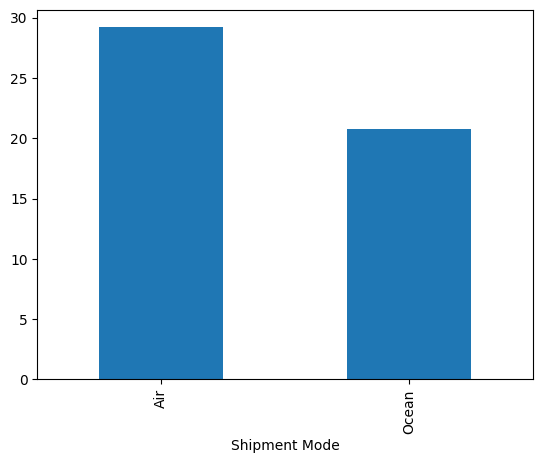

In [6]:
h1 = sub.groupby("Shipment Mode")["cost_per_kg"].mean()
h1.plot(kind="bar")

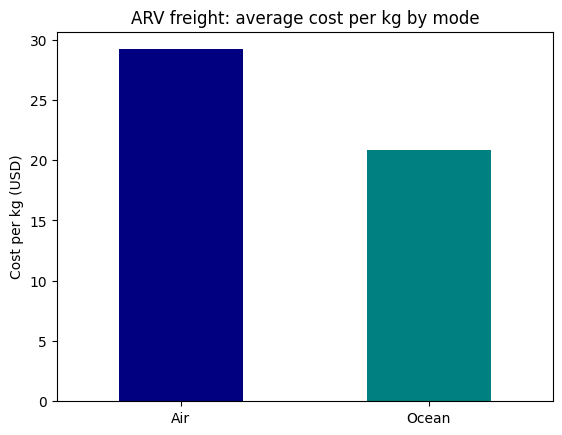

In [7]:
import matplotlib.pyplot as plt

h1.plot(kind="bar", color=["navy", "teal"])
plt.title("ARV freight: average cost per kg by mode")
plt.ylabel("Cost per kg (USD)")
plt.xlabel("")
plt.xticks(rotation=0)
plt.show()

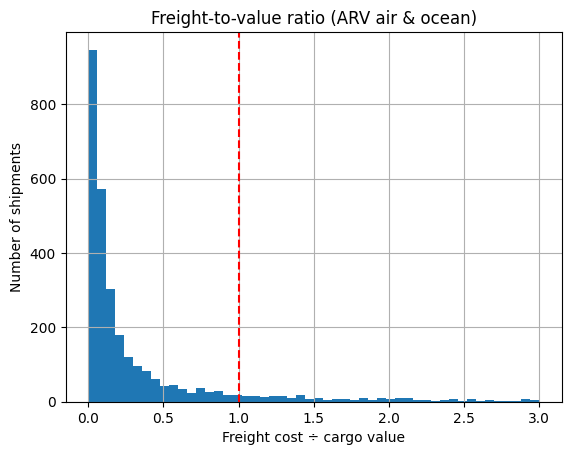

In [9]:
sub['freight_clean'] = pd.to_numeric(sub['freight_clean'], errors='coerce')

sub['Line Item Value'] = pd.to_numeric(sub['Line Item Value'], errors='coerce')

sub['ratio'] = sub['freight_clean'] / sub['Line Item Value']

import matplotlib.pyplot as plt

sub["ratio"].hist(bins=50, range=(0, 3))
plt.title("Freight-to-value ratio (ARV air & ocean)")
plt.xlabel("Freight cost ÷ cargo value")
plt.ylabel("Number of shipments")
plt.axvline(1, color="red", linestyle="--")
plt.show()